# 01 · Entrada de dados, ETL e engenharia de atributos

**Trabalho N3 – Análise Preditiva · Projeto Integrador de MLOps**

Este notebook executa os passos **2 e 3 do fluxo único** (entrada/versionamento de dados novos → ETL, validação e engenharia de atributos) e o monitoramento de drift do critério 10. Todas as funções reutilizáveis estão em `src/`; aqui documentamos o processo e as evidências.

| Passo do fluxo | O que acontece aqui |
|---|---|
| 2. Entrada e versionamento | lotes novos em `data/raw/` são detectados (ou a chegada é simulada), validados e registrados com SHA-256 → `data_version` |
| 3. ETL e atributos | diagnóstico antes/depois, limpeza justificada, extração de atributos, partição por hash e ajuste do `ColumnTransformer` **somente no treino** |
| Critério 10 | PSI dos lotes novos vs. perfil do modelo vigente + desempenho do vigente no lote novo |

In [1]:
import sys
from pathlib import Path

# Caminhos consistentes: localiza a raiz do projeto (pasta com config/config.yaml)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(RAIZ))
from src.config import preparar_notebook

cfg = preparar_notebook()  # muda o diretório de trabalho para a raiz do projeto

import json

import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (9, 4)})

from src import ciclo, ingestao, monitoramento, rastreamento
from src import preprocessamento as pp
from src.config import relativo, salvar_json
from src.modelagem import calcular_metricas, codificar_alvo
from src.promocao import carregar_vigente

## Etapa 1 – Problema, dados e avaliação (definidos antes do treinamento)

A definição do problema, a métrica e o protocolo vêm de `config/config.yaml` e são registrados no MLflow a cada ciclo.

In [2]:
prob, dados, aval, part = cfg["problema"], cfg["dados"], cfg["avaliacao"], cfg["particionamento"]
display(Markdown(f"""
| Item | Definição |
|---|---|
| Tipo | {prob['tipo']} |
| Unidade de observação | {prob['unidade_observacao']} |
| Variável-alvo | `{prob['variavel_alvo']}` ∈ {dados['classes']} |
| Atributos | {len(pp.COLUNAS_NUMERICAS)} numéricos léxicos + {len(pp.COLUNAS_CATEGORICAS)} categórico (TLD), extraídos só do texto da URL |
| Fonte / licença | [{dados['fonte']['nome']}]({dados['fonte']['url']}) – {dados['fonte']['licenca']} |
| Chegada de dados | lote inicial de {dados['chegada']['tamanho_lote_inicial']:,} linhas; +{dados['chegada']['tamanho_lote_novo']:,} por ciclo |
| Métrica principal | **{aval['metrica_principal']}** ({aval['direcao']}) – {aval['justificativa'].strip()} |
| Particionamento | hash da URL: teste {part['proporcao_teste']:.0%} (reservado), validação {part['proporcao_validacao']:.0%} (promoção), treino {1 - part['proporcao_teste'] - part['proporcao_validacao']:.0%} com StratifiedKFold k={aval['cv_folds']} |
"""))


| Item | Definição |
|---|---|
| Tipo | classificacao_multiclasse |
| Unidade de observação | uma URL (string) coletada de listas públicas de ameaças e de sites legítimos |
| Variável-alvo | `type` ∈ ['benign', 'defacement', 'phishing', 'malware'] |
| Atributos | 38 numéricos léxicos + 1 categórico (TLD), extraídos só do texto da URL |
| Fonte / licença | [Malicious URLs dataset (Kaggle)](https://www.kaggle.com/datasets/sid321axn/malicious-urls-dataset) – CC0: Public Domain (conforme a página do dataset no Kaggle) |
| Chegada de dados | lote inicial de 30,000 linhas; +5,000 por ciclo |
| Métrica principal | **f1_macro** (maximizar) – As classes são desbalanceadas (benign é maioria). A F1 macro dá o mesmo peso a cada classe e penaliza modelos que ignoram classes minoritárias como malware, que são justamente as de maior custo de erro. |
| Particionamento | hash da URL: teste 15% (reservado), validação 15% (promoção), treino 70% com StratifiedKFold k=5 |


**Limitações conhecidas dos dados.** O dataset agrega listas públicas de origens diferentes (ISCX-URL-2016, PhishTank, PhishStorm, listas de malware), com vieses de coleta (formato da URL diferente por fonte — tratado no ETL abaixo) e algum ruído de rótulo (há URLs legítimas rotuladas como phishing). As métricas, portanto, refletem este dataset e não garantem o mesmo desempenho em tráfego real. Não é série temporal: a ordem dos lotes é simulada a partir de uma permutação com semente fixa.

## Passo 2 – Ciclo, entrada e versionamento dos dados

O `cycle_id` foi criado pelo workflow (`python -m src.ciclo novo`) ou é criado agora, se o notebook for executado manualmente.

In [3]:
ctx = ciclo.obter_ou_criar_para_etl()
EVID = ciclo.dir_evidencias(ctx)
print(f"cycle_id = {ctx['cycle_id']}  |  gatilho = {ctx['gatilho']}  |  evidências em {ctx['dir_evidencias']}")

registro, pendentes, avisos = ingestao.receber_lotes(cfg, ctx)
for aviso in avisos:
    print("AVISO:", aviso)
print(f"Lotes pendentes de incorporação neste ciclo: {[l['arquivo'] for l in pendentes]}")

cycle_id = c0005-20261123T211722Z  |  gatilho = schedule  |  evidências em evidencias/c0005-20261123T211722Z


Lotes pendentes de incorporação neste ciclo: ['data/raw/lote_0005.csv']


### Validação de qualidade de cada lote recebido

Um lote só é incorporado se pelo menos `proporcao_minima_validos_lote` das linhas forem válidas (URL e rótulo presentes, rótulo conhecido, comprimento plausível). Lotes reprovados ficam registrados como `rejeitado` e não contaminam o treino.

In [4]:
qual = cfg["dados"]["qualidade"]
aceitos, rejeitados, linhas_diag = [], {}, []
for lote in pendentes:
    d = pp.diagnosticar(ingestao.ler_lote(cfg, lote), cfg)
    invalidas = d["url_ausente"] + d["alvo_ausente"] + d["url_vazia"] + d["rotulo_invalido"] + d["acima_comprimento_maximo"]
    prop_validas = 1 - invalidas / max(d["linhas"], 1)
    aprovado = prop_validas >= qual["proporcao_minima_validos_lote"]
    if aprovado:
        aceitos.append(lote)
    else:
        rejeitados[lote["arquivo"]] = f"apenas {prop_validas:.1%} de linhas válidas"
    linhas_diag.append({"lote": lote["arquivo"], "linhas": d["linhas"], "proporcao_validas": round(prop_validas, 4),
                        "duplicadas_no_lote": d["linhas_duplicadas"], "aprovado": aprovado})
diag_lotes = pd.DataFrame(linhas_diag)
display(diag_lotes)

data_version = ingestao.finalizar_incorporacao(cfg, registro, ctx, aceitos, rejeitados)
ctx["data_version"] = data_version
ciclo.salvar_ciclo(ctx)
print(f"data_version = {data_version}")
display(pd.DataFrame(registro["lotes"])[["arquivo", "linhas", "origem", "status", "recebido_no_ciclo", "sha256"]].assign(sha256=lambda d: d.sha256.str[:12]))

,lote,linhas,proporcao_validas,duplicadas_no_lote,aprovado
0,data/raw/lote_0005.csv,5000,1.0,6,True


data_version = dv005-e930a6b0


,arquivo,linhas,origem,status,recebido_no_ciclo,sha256
0,data/raw/lote_0001.csv,30000,simulacao_fonte_publica,incorporado,NaN,8ac2625089e2
1,data/raw/lote_0002.csv,5000,simulacao_fonte_publica,incorporado,c0002-20261120T174720Z,ee432a455190
2,data/raw/lote_0003.csv,5000,simulacao_fonte_publica,incorporado,c0003-20261121T164655Z,439c25818792
3,data/raw/lote_0004.csv,5000,simulacao_fonte_publica,incorporado,c0004-20261122T170836Z,796a2279f4b2
4,data/raw/lote_0005.csv,5000,simulacao_fonte_publica,incorporado,c0005-20261123T211722Z,547748d500f9


In [5]:
# Run pai do ciclo no MLflow (todas as etapas serão runs filhos com o mesmo cycle_id/data_version)
ctx["mlflow_run_pai"] = rastreamento.criar_run_pai(ctx, cfg)
ciclo.salvar_ciclo(ctx)
print("Run pai do ciclo:", ctx["mlflow_run_pai"])

Run pai do ciclo: d9c0aa0272734360ab069dc0664dfec2


## Passo 3 – ETL: diagnóstico antes/depois e limpeza

Todos os lotes incorporados são consolidados na ordem de chegada. Em duplicações, a **primeira** ocorrência é mantida — registros repetidos em lotes novos não entram duas vezes.

In [6]:
bruto = ingestao.carregar_lotes_incorporados(cfg, registro)
diag_antes = pp.diagnosticar(bruto, cfg)
limpo, acoes = pp.limpar(bruto, cfg)
diag_depois = pp.diagnosticar(limpo, cfg)

chaves = [k for k in diag_antes if k != "distribuicao_classes"]
antes_depois = pd.DataFrame({"antes": [diag_antes[k] for k in chaves], "depois": [diag_depois[k] for k in chaves]}, index=chaves)
display(antes_depois)
display(pd.DataFrame(acoes))
display(pd.DataFrame({"antes": diag_antes["distribuicao_classes"], "depois": diag_depois["distribuicao_classes"]}))

,antes,depois
linhas,50000.00,49701.0
url_ausente,0.00,0.0
alvo_ausente,0.00,0.0
url_vazia,0.00,0.0
espacos_nas_bordas,0.00,0.0
rotulo_invalido,0.00,0.0
linhas_duplicadas,299.00,0.0
urls_repetidas,299.00,0.0
urls_com_rotulos_conflitantes,0.00,0.0
comprimento_mediano,47.00,47.0


,acao,removidos,restantes,justificativa
0,remover_ausentes,0,50000,Sem URL ou sem rótulo não há como extrair atri...
1,normalizar_e_remover_vazias,0,50000,Espaços nas bordas são ruído de coleta; URL va...
2,remover_rotulos_invalidos,0,50000,Somente as classes previstas no problema: ['be...
3,remover_urls_corrompidas,0,50000,URLs acima de 2048 caracteres excedem limites ...
4,remover_conflitos_de_rotulo,0,50000,A mesma URL com rótulos diferentes é inconsist...
5,remover_duplicadas,299,49701,Cada URL entra uma única vez; mantém a ocorrên...


,antes,depois
benign,32767,32767
defacement,7402,7397
phishing,7345,7344
malware,2486,2193


In [7]:
nomes_aceitos = {Path(l["arquivo"]).stem for l in aceitos}
limpo["novo_no_ciclo"] = limpo["lote"].isin(nomes_aceitos)
por_lote = limpo.groupby("lote").size().rename("registros_unicos_apos_limpeza").to_frame()
por_lote["linhas_brutas"] = bruto.groupby("lote").size()
por_lote["descartados"] = por_lote["linhas_brutas"] - por_lote["registros_unicos_apos_limpeza"]
display(por_lote)
print(f"Registros novos incorporados neste ciclo (únicos, válidos): {int(limpo['novo_no_ciclo'].sum())}")

,registros_unicos_apos_limpeza,linhas_brutas,descartados
lote,,,
lote_0001,29875,30000,125
lote_0002,4960,5000,40
lote_0003,4950,5000,50
lote_0004,4955,5000,45
lote_0005,4961,5000,39


Registros novos incorporados neste ciclo (únicos, válidos): 4961


### Inconsistência de formato entre fontes (viés de coleta)

As classes vêm de fontes diferentes e cada fonte grava a URL num formato. A tabela abaixo mostra, por classe, a proporção de URLs com esquema (`http://`/`https://`), com `www.` e — entre as URLs só de domínio — terminadas em `/`: praticamente nenhuma benigna tem esquema, todas as de *defacement* têm, e quase todo domínio benigno termina em `/` (fonte DMOZ), ao contrário dos de phishing. Um modelo treinado assim aprende o **formato da fonte**, não o risco da URL — durante o desenvolvimento, `https://www.google.com` foi classificada como phishing. **Tratamento:** a URL é normalizada (sem esquema, sem `www.` e sem `/` final) antes da extração de atributos, e nenhum atributo deriva desses elementos.

In [8]:
url_baixa = limpo["url"].str.lower()
sem_prefixo = url_baixa.str.replace(r"^(?:[a-z][a-z0-9+.\-]*://)?(?:www\d?\.)?", "", regex=True)
so_dominio = ~sem_prefixo.str.rstrip("/").str.contains("[/?]", regex=True)
vies = pd.DataFrame({
    "com_esquema": url_baixa.str.match(r"^[a-z][a-z0-9+.\-]*://"),
    "https": url_baixa.str.startswith("https://"),
    "www": url_baixa.str.match(r"^(?:[a-z][a-z0-9+.\-]*://)?www\d?\."),
    "barra_final_dominio": sem_prefixo.str.endswith("/").astype(float).where(so_dominio),
    "type": limpo["type"],
}).groupby("type").mean().round(3)
display(vies)
print("Exemplos de normalização:", [(u, pp.normalizar_url(u)) for u in ["https://www.google.com/", "http://site.com/a?b=1", "www2.banco.com.br/"]])

,com_esquema,https,www,barra_final_dominio
type,,,,
benign,0.082,0.005,0.031,0.994
defacement,1.000,0.000,0.705,NaN
malware,0.960,0.238,0.070,0.066
phishing,0.271,0.079,0.391,0.079


Exemplos de normalização: [('https://www.google.com/', 'google.com'), ('http://site.com/a?b=1', 'site.com/a?b=1'), ('www2.banco.com.br/', 'banco.com.br')]


## Engenharia de atributos

`extrair_features` transforma cada URL normalizada em atributos léxicos (comprimentos, contagens de caracteres, presença de IP/porta/encurtador/extensão executável, palavras suspeitas, entropia, TLD...). A função não tem estado — não aprende nada dos dados —, portanto pode ser aplicada antes da partição sem vazamento.

,url_length,num_dots,path_depth,has_ip,num_suspicious_words,entropy
type,,,,,,
benign,56.448,1.904,2.210,0.000,0.161,4.192
defacement,76.614,2.133,1.809,0.000,0.016,4.369
malware,46.034,2.834,1.822,0.415,0.041,4.059
phishing,42.029,2.057,1.742,0.003,0.235,3.965


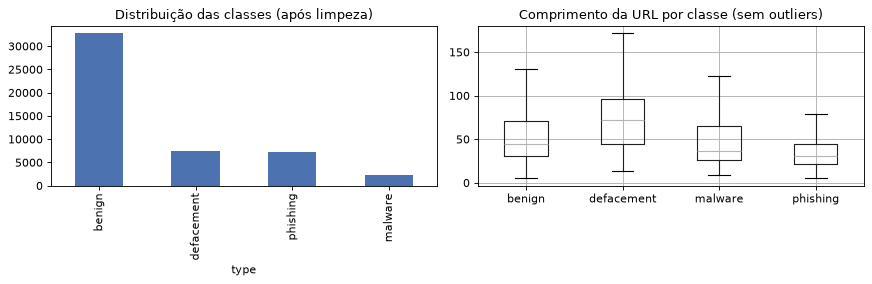

In [9]:
X = pp.extrair_features_lote(limpo["url"])
base = pd.concat([limpo[["url", "type", "lote", "novo_no_ciclo"]], X], axis=1)
display(base.groupby("type")[["url_length", "num_dots", "path_depth", "has_ip", "num_suspicious_words", "entropy"]].mean().round(3))

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8))
base["type"].value_counts().plot.bar(ax=eixos[0], color="#4C72B0", title="Distribuição das classes (após limpeza)")
base.boxplot(column="url_length", by="type", ax=eixos[1], showfliers=False)
eixos[1].set_title("Comprimento da URL por classe (sem outliers)"); eixos[1].set_xlabel(""); fig.suptitle("")
fig.tight_layout(); fig.savefig(EVID / "etl_distribuicoes.png"); plt.show()

## Particionamento sem vazamento

A partição é função apenas do hash da URL (com sal fixo). Assim, uma URL nunca muda de partição entre ciclos, o conjunto de **teste** (15%) nunca é usado em decisões e a **validação** (15%) serve apenas para comparar desafiante e vigente na promoção. As decisões recorrentes (votação e eleição A×B) usam validação cruzada **dentro do treino**.

In [10]:
base["particao"] = pp.particionar(base["url"], cfg)
assert base["url"].is_unique, "URLs duplicadas após a limpeza"
assert (pp.particionar(base["url"].head(500), cfg) == base["particao"].head(500)).all(), "partição não determinística"
display(pd.crosstab(base["particao"], base["type"], normalize="index").round(3).assign(n=base["particao"].value_counts()))

type,benign,defacement,malware,phishing,n
particao,,,,,
teste,0.664,0.147,0.042,0.148,7484
treino,0.658,0.149,0.045,0.149,34878
validacao,0.660,0.152,0.044,0.144,7339


## Pré-processamento ajustado somente no treino (`ColumnTransformer`)

* numéricos: imputação pela mediana → winsorização nos quantis 0,1%/99,9% (outliers) → padronização;
* categórico (TLD): imputação constante → one-hot com categoria "infrequente" para TLDs raros/desconhecidos.

O mesmo `ColumnTransformer` é reconstruído dentro do pipeline de cada modelo e serializado junto com ele.

In [11]:
treino = base[base["particao"] == "treino"]
prep = pp.construir_preprocessador(cfg).fit(treino[pp.COLUNAS_FEATURES])
Xt_treino = prep.transform(treino[pp.COLUNAS_FEATURES])
Xt_val = prep.transform(base.loc[base["particao"] == "validacao", pp.COLUNAS_FEATURES])
print(f"{len(pp.COLUNAS_FEATURES)} atributos brutos -> {Xt_treino.shape[1]} colunas após o ColumnTransformer")
display(pd.DataFrame({"media_treino": Xt_treino.mean(), "desvio_treino": Xt_treino.std(), "media_validacao": Xt_val.mean()}).round(3).head(12))

DIR_PROC = Path(cfg["dados"]["dir_processed"]); DIR_PROC.mkdir(parents=True, exist_ok=True)
base.to_parquet(DIR_PROC / "base_features.parquet", index=False)
joblib.dump(prep, DIR_PROC / "preprocessador_treino.joblib");

39 atributos brutos -> 56 colunas após o ColumnTransformer


,media_treino,desvio_treino,media_validacao
url_length,-0.0,1.0,0.005
host_length,-0.0,1.0,0.005
path_length,-0.0,1.0,-0.006
query_length,0.0,1.0,0.009
num_dots,0.0,1.0,-0.012
num_slash,0.0,1.0,0.001
num_hyphen,-0.0,1.0,0.007
num_underscore,0.0,1.0,-0.007
num_at,0.0,1.0,0.021
num_question,0.0,1.0,-0.002


## Critério 10 – Monitoramento de drift do lote novo

Compara as features dos registros que chegaram **neste ciclo** com o perfil de referência guardado no modelo vigente (PSI por feature) e mede a F1 macro do vigente nesses registros **antes** do re-treino. Para mostrar que o detector funciona, aplicamos o mesmo cálculo a uma amostra de controle deliberadamente enviesada (apenas URLs de phishing), que deve disparar alerta.

In [12]:
mon = {"cycle_id": ctx["cycle_id"], "data_version": data_version, "lotes": sorted(nomes_aceitos),
       "n_registros_novos": int(base["novo_no_ciclo"].sum()), "nivel": "sem_referencia", "motivos": []}
manifesto, vigente = carregar_vigente()
novos = base[base["novo_no_ciclo"]]
if vigente is not None and vigente.perfil_referencia and len(novos) > 0:
    drift = monitoramento.calcular_drift(vigente.perfil_referencia, novos[pp.COLUNAS_FEATURES], cfg)
    proba = vigente.prever_proba_features(novos[pp.COLUNAS_FEATURES])
    m_lote = calcular_metricas(codificar_alvo(novos["type"], cfg["dados"]["classes"]), proba, cfg["dados"]["classes"])
    ref = manifesto["vigente"]["valor_metrica_validacao"]
    mon["drift"] = drift
    mon["desempenho_vigente_no_lote"] = {"versao": manifesto["vigente"]["versao"], "f1_macro_lote": m_lote["f1_macro"],
                                          "f1_macro_referencia": ref, "queda_f1": ref - m_lote["f1_macro"]}
    mon["nivel"], mon["motivos"] = monitoramento.consolidar_nivel(drift, ref - m_lote["f1_macro"], cfg)
    controle = base[(base["particao"] == "treino") & (base["type"] == "phishing")]
    mon["teste_sensibilidade"] = {k: v for k, v in monitoramento.calcular_drift(vigente.perfil_referencia, controle[pp.COLUNAS_FEATURES], cfg).items() if k != "psi_por_feature"}
    display(pd.Series(drift["psi_por_feature"]).head(10).rename("PSI (lote novo)").to_frame())
    print(f"Nível consolidado: {mon['nivel']}  |  motivos: {mon['motivos'] or '-'}")
    print(f"Controle enviesado (só phishing): PSI máx = {mon['teste_sensibilidade']['psi_max']:.3f} -> {mon['teste_sensibilidade']['nivel_drift']}")
else:
    print("Sem modelo vigente com perfil de referência (primeiro ciclo) ou sem registros novos: drift não calculado.")
salvar_json(mon, EVID / "monitoramento_drift.json");

,PSI (lote novo)
tld,0.00779
path_length,0.00332
num_path_tokens,0.00268
longest_token,0.00217
num_letters,0.00183
ratio_letters,0.00180
ratio_special,0.00148
entropy,0.00144
url_length,0.00142
num_special,0.00136


Nível consolidado: estavel  |  motivos: -
Controle enviesado (só phishing): PSI máx = 0.406 -> alerta


## Registro no MLflow e evidências do ciclo

In [13]:
contagem_part = base["particao"].value_counts().to_dict()
salvar_json({"antes": diag_antes, "depois": diag_depois, "acoes": acoes, "particoes": contagem_part,
             "particao_x_classe": pd.crosstab(base["particao"], base["type"]).to_dict(orient="index"),
             "vies_coleta": vies.to_dict(orient="index"), "n_features_brutas": len(pp.COLUNAS_FEATURES),
             "n_colunas_transformadas": int(Xt_treino.shape[1])}, EVID / "etl_resumo.json")
antes_depois.to_csv(EVID / "etl_diagnostico_antes_depois.csv")
pd.DataFrame(acoes).to_csv(EVID / "etl_acoes_limpeza.csv", index=False)
diag_lotes.to_csv(EVID / "etl_validacao_lotes.csv", index=False)
salvar_json(registro, EVID / "registro_lotes.json")

with rastreamento.run_etapa(ctx, cfg, "01_etl", "01_etl") as run:
    mlflow.log_params({
        "lotes_incorporados": len(ingestao.lotes_por_status(registro, "incorporado")),
        "lotes_novos": ",".join(sorted(nomes_aceitos)) or "nenhum",
        "lotes_rejeitados": ",".join(rejeitados) or "nenhum",
        "metrica_principal": cfg["avaliacao"]["metrica_principal"], "direcao": cfg["avaliacao"]["direcao"],
        "particionamento": f"hash teste={part['proporcao_teste']} validacao={part['proporcao_validacao']}",
    })
    mlflow.log_metrics({"linhas_brutas": len(bruto), "registros_limpos": len(base), "registros_novos": mon["n_registros_novos"],
                        **{f"n_{k}": v for k, v in contagem_part.items()}})
    if "drift" in mon:
        mlflow.log_metrics({"psi_max": mon["drift"]["psi_max"], "f1_vigente_lote_novo": mon["desempenho_vigente_no_lote"]["f1_macro_lote"]})
    mlflow.set_tag("nivel_drift", mon["nivel"])
    mlflow.log_artifacts(str(EVID), artifact_path="evidencias_etl")
    run_id_etl = run.info.run_id

rastreamento.atualizar_run_pai(ctx, tags={"nivel_drift": mon["nivel"], "lotes_novos": ",".join(sorted(nomes_aceitos)) or "nenhum"},
                               metricas={"registros_limpos": len(base), "registros_novos": mon["n_registros_novos"]})
ctx = ciclo.registrar_etapa(ctx, "01_etl", run_id=run_id_etl, registros=len(base), registros_novos=mon["n_registros_novos"],
                            lotes_novos=sorted(nomes_aceitos), particoes=contagem_part)
print(f"Etapa 01 concluída | cycle_id={ctx['cycle_id']} | data_version={ctx['data_version']} | run_id={run_id_etl}")

🏃 View run c0005-20261123T211722Z/01_etl at: http://127.0.0.1:5000/#/experiments/1/runs/16cdde3f0a1f4beaa79f57aab237aa74
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Etapa 01 concluída | cycle_id=c0005-20261123T211722Z | data_version=dv005-e930a6b0 | run_id=16cdde3f0a1f4beaa79f57aab237aa74
